In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize

In [2]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

In [3]:
# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=int((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [4]:
folder='/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/'
path=folder+'inversions_new/TM5_3_years/'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
savefig='figures_2/stations_distribution/'


In [5]:
savefig='figures_2/stations_distribution/'
inversion_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/'
flux_path=f'{inversion_path}/{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
fluxes=xr.open_dataset(flux_path)
fluxes['time']=pd.to_datetime(fluxes.time)
fluxes=fluxes.where((fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)

gosat_data=xr.open_dataset(inversion_path+f'gosat_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')

tccon_data=xr.open_dataset(inversion_path+f'TCCON_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')

insitu_data=xr.open_dataset(inversion_path+f'insitu_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')


In [6]:
folder='/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/'
path=folder+'inversions_new/TM5_correlations/'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
savefig='figures_2/stations_distribution/'


In [7]:
savefig='figures_2/stations_distribution/'
inversion_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/'
flux_path=f'{inversion_path}/{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc'
fluxes=xr.open_dataset(flux_path)
fluxes['time']=pd.to_datetime(fluxes.time)
fluxes=fluxes.where((fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)

gosat_data=xr.open_dataset(inversion_path+f'gosat_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
gosat_data=gosat_data.where((gosat_data.release_time>=pd.to_datetime(analysis_start_date))&(gosat_data.release_time<=pd.to_datetime(analysis_end_date)),drop=True)
#gosat_data=gosat_data.where((gosat_data.release_lat>analy_region_lat[0])&(gosat_data.release_lat<analy_region_lat[1])&(gosat_data.release_lon>analy_region_lon[0])&(gosat_data.release_lon<analy_region_lon[1]),drop=True)

tccon_data=xr.open_dataset(inversion_path+f'TCCON_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
tccon_data=tccon_data.where((tccon_data.release_time>=pd.to_datetime(analysis_start_date))&(tccon_data.release_time<=pd.to_datetime(analysis_end_date)),drop=True)
#tccon_data=tccon_data.where((tccon_data.release_lat>analy_region_lat[0])&(tccon_data.release_lat<analy_region_lat[1])&(tccon_data.release_lon>analy_region_lon[0])&(tccon_data.release_lon<analy_region_lon[1]),drop=True)

insitu_data=xr.open_dataset(inversion_path+f'insitu_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
insitu_data=insitu_data.where((insitu_data.release_time>=pd.to_datetime(analysis_start_date))&(insitu_data.release_time<=pd.to_datetime(analysis_end_date)),drop=True)
#insitu_data=insitu_data.where((insitu_data.release_lat>analy_region_lat[0])&(insitu_data.release_lat<analy_region_lat[1])&(insitu_data.release_lon>analy_region_lon[0])&(insitu_data.release_lon<analy_region_lon[1]),drop=True)

gosat_summer=gosat_data.where((gosat_data.release_time.dt.month==5) | (gosat_data.release_time.dt.month==6) | (gosat_data.release_time.dt.month==7), drop=True)
gosat_winter=gosat_data.where((gosat_data.release_time.dt.month==11) | (gosat_data.release_time.dt.month==12) | (gosat_data.release_time.dt.month==1), drop=True)

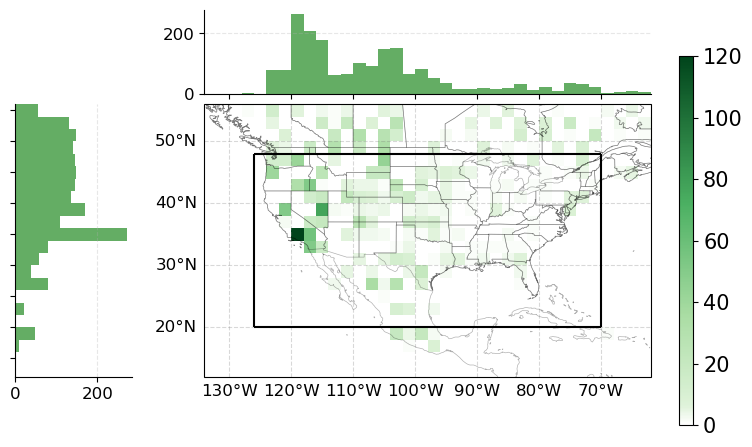

In [8]:
flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable

lat_centers = np.arange(flexpart_region[0] + 1, flexpart_region[1], 2)
lon_centers = np.arange(flexpart_region[2] + 1, flexpart_region[3], 2)

lat_idx = np.abs(gosat_summer.release_lat.values[..., np.newaxis] - lat_centers).argmin(axis=-1)
lon_idx = np.abs(gosat_summer.release_lon.values[..., np.newaxis] - lon_centers).argmin(axis=-1)
counts = np.zeros((len(lat_centers), len(lon_centers)), dtype=int)
for i, j in zip(lat_idx.ravel(), lon_idx.ravel()):
    counts[i, j] += 1


# Sum map counts along latitude/longitude
lon_counts = counts.sum(axis=0)
lat_counts = counts.sum(axis=1)


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig = plt.figure(figsize=(9, 7))

# Map occupies bottom-right
ax_map = fig.add_axes([0.22, 0.15, 0.62, 0.62], projection=ccrs.PlateCarree())


# ---------------------------------------------------------
# Map
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_green',[(0.00, 'white'), (0.05, plt.cm.Greens(0.15)), (0.30, plt.cm.Greens(0.35)), (0.60, plt.cm.Greens(0.60)), (1.00, plt.cm.Greens(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
mesh = ax_map.pcolormesh(lon_grid, lat_grid, counts, cmap=cmap, norm=norm, shading='auto')
cbar = plt.colorbar(mesh, ax=ax_map, location='right', shrink=0.85, aspect=25, pad=0.05)
cbar.ax.tick_params(labelsize=15)
ax_map.coastlines(linewidth=0.5, alpha=0.3)
ax_map.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_map.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_map.set_xlim(-134, -62)
ax_map.set_ylim(12, 56)
ax_map.tick_params(axis='both', labelsize=16)
fig.canvas.draw()


ax_map.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_map.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')


map_pos = ax_map.get_position()

x0 = map_pos.x0
y0 = map_pos.y0
width = map_pos.width
height = map_pos.height
# ---------------------------------------------------------
# Marginal histograms
# ---------------------------------------------------------


hist_height = 0.12
hist_width = 0.13
gap = 0.015
# Longitude histogram
ax_lon = fig.add_axes([ x0, y0 + height + gap, width, hist_height])
# Latitude histogram
ax_lat = fig.add_axes([ x0 - hist_width - 0.08, y0, hist_width, height])

# Sum map counts along latitude/longitude
lon_counts = counts.sum(axis=0)
lat_counts = counts.sum(axis=1)


# Longitude histogram
ax_lon.bar(lon_centers, lon_counts, width=2, align='center', color='forestgreen', alpha=0.7)
ax_lon.set_xlim(-134, -62)
ax_lon.tick_params(axis='x', labelbottom=False)
ax_lon.tick_params(axis='y', labelsize=12)
ax_lon.grid(axis='y', linestyle='--', alpha=0.3)
# Remove unnecessary borders
ax_lon.spines['right'].set_visible(False)
ax_lon.spines['top'].set_visible(False)


# Left: latitude distribution

ax_lat.barh( lat_centers, lat_counts, height=2, align='center', color='forestgreen', alpha=0.7)
ax_lat.set_ylim(12, 56)
ax_lat.tick_params( axis='y', labelleft=False)
ax_lat.tick_params( axis='x', labelsize=12)

ax_lat.grid( axis='x', linestyle='--', alpha=0.3)
ax_lat.spines['right'].set_visible(False)
ax_lat.spines['top'].set_visible(False)

plt.savefig(f'{savefig}/gosat_meas_distribution_summer.pdf',bbox_inches='tight')#,transparent=True)

plt.show()


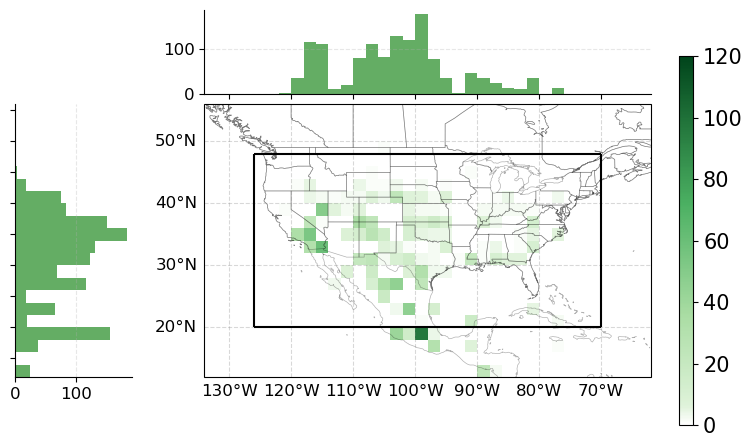

In [9]:
flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable

lat_centers = np.arange(flexpart_region[0] + 1, flexpart_region[1], 2)
lon_centers = np.arange(flexpart_region[2] + 1, flexpart_region[3], 2)

lat_idx = np.abs(gosat_winter.release_lat.values[..., np.newaxis] - lat_centers).argmin(axis=-1)
lon_idx = np.abs(gosat_winter.release_lon.values[..., np.newaxis] - lon_centers).argmin(axis=-1)
counts = np.zeros((len(lat_centers), len(lon_centers)), dtype=int)
for i, j in zip(lat_idx.ravel(), lon_idx.ravel()):
    counts[i, j] += 1


# Sum map counts along latitude/longitude
lon_counts = counts.sum(axis=0)
lat_counts = counts.sum(axis=1)


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig = plt.figure(figsize=(9, 7))

# Map occupies bottom-right
ax_map = fig.add_axes([0.22, 0.15, 0.62, 0.62], projection=ccrs.PlateCarree())


# ---------------------------------------------------------
# Map
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_green',[(0.00, 'white'), (0.05, plt.cm.Greens(0.15)), (0.30, plt.cm.Greens(0.35)), (0.60, plt.cm.Greens(0.60)), (1.00, plt.cm.Greens(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
mesh = ax_map.pcolormesh(lon_grid, lat_grid, counts, cmap=cmap, norm=norm, shading='auto')
cbar = plt.colorbar(mesh, ax=ax_map, location='right', shrink=0.85, aspect=25, pad=0.05)
cbar.ax.tick_params(labelsize=15)
ax_map.coastlines(linewidth=0.5, alpha=0.3)
ax_map.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_map.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_map.set_xlim(-134, -62)
ax_map.set_ylim(12, 56)
ax_map.tick_params(axis='both', labelsize=20)
fig.canvas.draw()

ax_map.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_map.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')


map_pos = ax_map.get_position()

x0 = map_pos.x0
y0 = map_pos.y0
width = map_pos.width
height = map_pos.height
# ---------------------------------------------------------
# Marginal histograms
# ---------------------------------------------------------


hist_height = 0.12
hist_width = 0.13
gap = 0.015
# Longitude histogram
ax_lon = fig.add_axes([ x0, y0 + height + gap, width, hist_height])
# Latitude histogram
ax_lat = fig.add_axes([ x0 - hist_width - 0.08, y0, hist_width, height])

# Sum map counts along latitude/longitude
lon_counts = counts.sum(axis=0)
lat_counts = counts.sum(axis=1)


# Longitude histogram
ax_lon.bar(lon_centers, lon_counts, width=2, align='center', color='forestgreen', alpha=0.7)
ax_lon.set_xlim(-134, -62)
ax_lon.tick_params(axis='x', labelbottom=False)
ax_lon.tick_params(axis='y', labelsize=12)
ax_lon.grid(axis='y', linestyle='--', alpha=0.3)
# Remove unnecessary borders
ax_lon.spines['right'].set_visible(False)
ax_lon.spines['top'].set_visible(False)


# Left: latitude distribution

ax_lat.barh( lat_centers, lat_counts, height=2, align='center', color='forestgreen', alpha=0.7)
ax_lat.set_ylim(12, 56)
ax_lat.tick_params( axis='y', labelleft=False)
ax_lat.tick_params( axis='x', labelsize=12)

ax_lat.grid( axis='x', linestyle='--', alpha=0.3)
ax_lat.spines['right'].set_visible(False)
ax_lat.spines['top'].set_visible(False)

plt.savefig(f'{savefig}/gosat_meas_distribution_winter.pdf',bbox_inches='tight')#,transparent=True)

plt.show()


# 3 years

In [28]:
insitu_data=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/insitu/prep_footprints_TM5_3_years_flexpart_region/diurnal_amplitude_weekly/high_res_scaled_footprints_20191001-20230331_2x2_weekly.nc')

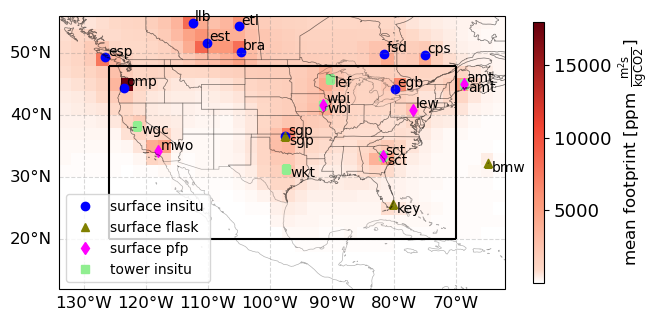

In [29]:
flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig = plt.figure(figsize=(9, 7))

# Map occupies bottom-right
ax_map = fig.add_axes([0.22, 0.15, 0.62, 0.62], projection=ccrs.PlateCarree())


# ---------------------------------------------------------
# Map
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
lat_centers = np.arange(flexpart_region[0] + 1, flexpart_region[1], 2)
lon_centers = np.arange(flexpart_region[2] + 1, flexpart_region[3], 2)
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
plot=insitu_data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_map,cmap=cmap, 
                                                                                cbar_kwargs={'location':'right', 
                                                                                             'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]',
                                                                                             'shrink':0.6, 
                                                                                             'aspect':25, 
                                                                                             'pad':0.05})
plot.colorbar.ax.yaxis.label.set_size(12)
plot.colorbar.ax.tick_params(labelsize=13)
ax_map.coastlines(linewidth=0.5, alpha=0.3)
ax_map.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_map.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_map.set_xlim(-134, -62)
ax_map.set_ylim(12, 56)
ax_map.tick_params(axis='both', labelsize=20)

ax_map.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_map.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()

files=[f for f in np.unique(insitu_data.file.values)]
# distinguish between surface and tower, insitu and flask
surf_is=[f for f in files if 'surface-insitu' in f]
surf_pfp=[f for f in files if 'surface-pfp' in f]
surf_flask=[f for f in files if 'surface-flask' in f]   # all flask meas
tower_is=[f for f in files if 'tower-insitu' in f]
release=insitu_data.drop_dims(['time','latitude','longitude'])
for f in tower_is:
    temp=release.where(release.file==f,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='s', color='lightgreen')
    ax_map.annotate(f[4:7], (temp.release_lon[0]+0.7, temp.release_lat[0]-1.3))
for f in surf_is:
    temp=release.where(release.file==f,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='o', color='blue')
    ax_map.annotate(f[4:7], (temp.release_lon[0]+0.4, temp.release_lat[0]+0.3))
for f in surf_flask:
    temp=release.where(release.file==f,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='^', color='olive')
    ax_map.annotate(f[4:7], (temp.release_lon[0]+0.7, temp.release_lat[0]-1.3))
for f in surf_pfp:
    temp=release.where(release.file==f,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='d', color='magenta')
    ax_map.annotate(f[4:7], (temp.release_lon[0]+0.4, temp.release_lat[0]+0.3))

# Manually create legend handles
custom_legend = [
    Line2D([0], [0], marker='o', label='surface insitu',color='blue', linestyle=''),
    Line2D([0], [0], marker='^', label='surface flask',color='olive', linestyle=''),
    Line2D([0], [0], marker='d', label='surface pfp',color='magenta', linestyle=''),
    Line2D([0], [0], marker='s', label='tower insitu',color='lightgreen', linestyle='')
]
# Add custom legend
ax_map.legend(handles=custom_legend, loc='lower left', fontsize=10)

ax_map.set_aspect(aspect=1)

plt.savefig(f'{savefig}/insitu_stations_3years.pdf',bbox_inches='tight')#,transparent=True)

plt.show()

In [30]:
three_year_period='20191001-20230331'
inversion_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/inversions_new/TM5_3_years/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/'
insitu_data=xr.open_dataset(inversion_path+f'insitu_data_2x2_{three_year_period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
insitu_meas=insitu_data.drop_dims(['time','latitude','longitude'])

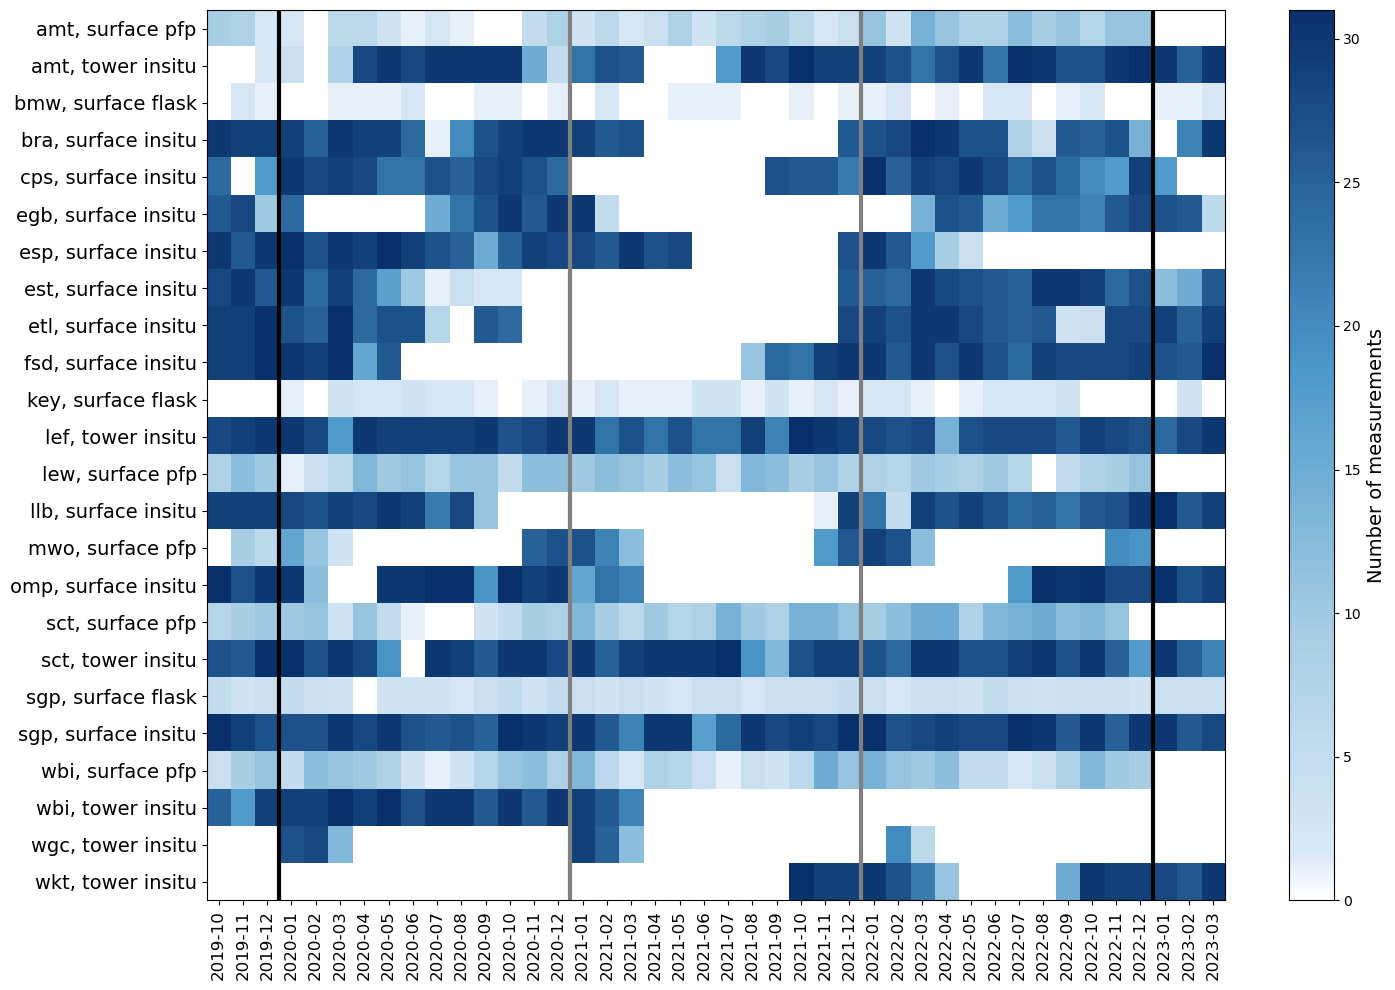

In [33]:
i_stations=np.unique(insitu_meas.file)
names=[]
for station in i_stations:
    temp = insitu_meas.where(insitu_meas.file == station, drop=True)
    #temp = temp.where((temp.release_time.dt.date >= start_date) &(temp.release_time.dt.date <= end_date), drop=True)
    times = pd.to_datetime(temp.release_time.values)
    # Count measurements per month
    # Put counts into the corresponding months
    station_name = station[4:7]
    if 'surface-insitu' in station:
        station_name+=', surface insitu'
    if 'surface-pfp' in station:
        station_name+=', surface pfp'
    if 'surface-flask' in station:
        station_name+=', surface flask'
    if 'tower-insitu' in station:
        station_name+=', tower insitu'
    names.append(station_name)

# Define monthly time axis
months = pd.date_range(start=dt.date(2019,10,1), end=dt.date(2023,3,31),freq="MS")
# Create empty station x month matrix
coverage = pd.DataFrame(0,index=names,columns=months)

cmap = LinearSegmentedColormap.from_list( 'white_blue',[(0.00, 'white'), (0.05, plt.cm.Blues(0.15)), (0.30, plt.cm.Blues(0.35)), (0.60, plt.cm.Blues(0.60)), (1.00, plt.cm.Blues(1.00)) ])

# Count measurements per month for each station
for k,station in enumerate(i_stations):
    temp = insitu_meas.where(insitu_meas.file == station, drop=True)
    #temp = temp.where((temp.release_time.dt.date >= start_date) &(temp.release_time.dt.date <= end_date), drop=True)
    times = pd.to_datetime(temp.release_time.values)
    # Count measurements per month
    counts = (pd.Series(times).dt.to_period("M").value_counts())

    for month, count in counts.items():
        month_timestamp = month.to_timestamp()
        if month_timestamp in coverage.columns:
            coverage.loc[names[k], month_timestamp] = count


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 10))
im = ax.imshow(
    coverage.values,
    aspect='auto',
    interpolation='none',
    cmap=cmap,
    vmin=0,
    vmax=coverage.values.max()
)

# y axis
ax.set_yticks(np.arange(len(coverage.index)))
ax.set_yticklabels(coverage.index ,fontsize=14)

# x axis
ax.set_xticks(np.arange(len(coverage.columns)))
ax.set_xticklabels(
    coverage.columns.strftime('%Y-%m'),
    rotation=90,
    ha='center',
    fontsize=12
)
ax.axvline(2.5,color='black',linewidth=3)
ax.axvline(38.5,color='black',linewidth=3)
ax.axvline(14.5,color='grey',linewidth=3)
ax.axvline(26.5,color='grey',linewidth=3)
#ax.set_xlabel('Time')
#ax.set_ylabel('Station')

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Number of measurements',fontsize=14)

plt.tight_layout()
plt.savefig(f'{savefig}/3years_insitu_measurements.pdf')

plt.show()

In [34]:
del insitu_data

In [35]:
tccon_data=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/TCCON/prep_footprints_TM5_3_years_flexpart_region/diurnal_amplitude_weekly/high_res_scaled_footprints_20191001-20230331_2x2_weekly.nc')

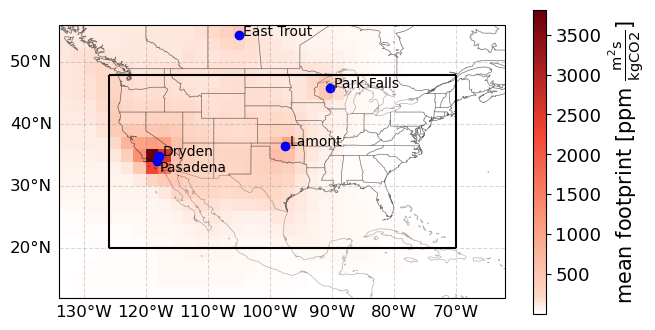

In [22]:
flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig = plt.figure(figsize=(9, 7))

# Map occupies bottom-right
ax_map = fig.add_axes([0.22, 0.15, 0.62, 0.62], projection=ccrs.PlateCarree())


# ---------------------------------------------------------
# Map
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
plot=tccon_data.spec001_mr.drop_vars('height').mean('pointspec').mean('time').plot(ax=ax_map,cmap=cmap, 
                                                                                cbar_kwargs={'location':'right', 'label':r'mean footprint [ppm $\mathrm{\frac{m^2s}{kgCO2}}$]','shrink':0.7, 'aspect':25, 'pad':0.05})
plot.colorbar.ax.yaxis.label.set_size(15)
plot.colorbar.ax.tick_params(labelsize=13)
ax_map.coastlines(linewidth=0.5, alpha=0.3)
ax_map.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_map.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_map.set_xlim(-134, -62)
ax_map.set_ylim(12, 56)
ax_map.tick_params(axis='both', labelsize=20)

ax_map.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_map.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

fig.canvas.draw()


map_pos = ax_map.get_position()
stations=np.unique(tccon_data.name)
for s in stations:
    temp=tccon_data.where(tccon_data.name==s,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='o', color='blue')
    if s=='Pasadena':
        ax_map.annotate(s, (temp.release_lon[0]+0.4, temp.release_lat[0]-1.7))
    else:
        ax_map.annotate(s, (temp.release_lon[0]+0.6, temp.release_lat[0]))
        
ax_map.set_aspect(aspect=1)
plt.savefig(f'{savefig}/tccon_stations.pdf',bbox_inches='tight')#,transparent=True)

plt.show()


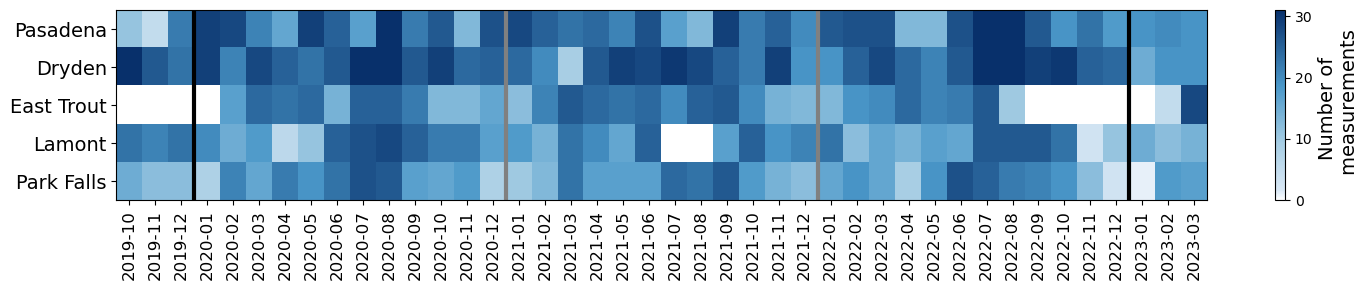

In [37]:
t_stations=np.unique(tccon_data.site_id)
names=[]
for station in t_stations:
    temp = tccon_data.where(tccon_data.site_id == station, drop=True)
    #temp = temp.where((temp.release_time.dt.date >= start_date) &(temp.release_time.dt.date <= end_date), drop=True)
    times = pd.to_datetime(temp.release_time.values)
    # Count measurements per month
    # Put counts into the corresponding months
    station_name = temp.name.values[0]
    names.append(station_name)

# Define monthly time axis
months = pd.date_range(start=dt.date(2019,10,1), end=dt.date(2023,3,31),freq="MS")
# Create empty station x month matrix
coverage = pd.DataFrame(0,index=names,columns=months)

cmap = LinearSegmentedColormap.from_list( 'white_blue',[(0.00, 'white'), (0.05, plt.cm.Blues(0.15)), (0.30, plt.cm.Blues(0.35)), (0.60, plt.cm.Blues(0.60)), (1.00, plt.cm.Blues(1.00)) ])

# Count measurements per month for each station
for k,station in enumerate(t_stations):
    temp = tccon_data.where(tccon_data.site_id == station, drop=True)
    #temp = temp.where((temp.release_time.dt.date >= start_date) &(temp.release_time.dt.date <= end_date), drop=True)
    times = pd.to_datetime(temp.release_time.values)
    # Count measurements per month
    counts = (pd.Series(times).dt.to_period("M").value_counts())

    for month, count in counts.items():
        month_timestamp = month.to_timestamp()
        if month_timestamp in coverage.columns:
            coverage.loc[names[k], month_timestamp] = count
            
# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(15, 3))
im = ax.imshow(
    coverage.values,
    aspect='auto',
    interpolation='none',
    cmap=cmap,
    vmin=0,
    vmax=coverage.values.max()
)

# y axis
ax.set_yticks(np.arange(len(coverage.index)))
ax.set_yticklabels(coverage.index,fontsize=14)

# x axis
ax.set_xticks(np.arange(len(coverage.columns)))
ax.set_xticklabels(
    coverage.columns.strftime('%Y-%m'),
    rotation=90,
    ha='center',
    fontsize=12
)

ax.axvline(2.5,color='black',linewidth=3)
ax.axvline(38.5,color='black',linewidth=3)
ax.axvline(14.5,color='grey',linewidth=3)
ax.axvline(26.5,color='grey',linewidth=3)
#ax.set_xlabel('Time')
#ax.set_ylabel('Station')

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Number of \n measurements',fontsize=14)

plt.tight_layout()
plt.savefig('figures_2/3years/tccon_measurements.pdf',bbox_inches='tight')
plt.show()


In [38]:
del tccon_data

In [39]:
gosat_data=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/RemoTeCv240/prep_footprints_TM5_3_years_flexpart_region/diurnal_amplitude_weekly/high_res_scaled_footprints_20191001-20230331_2x2_weekly.nc')

In [40]:
analysis_start_date, analysis_end_date =dt.date(2019,10,1), dt.date(2023,3,31)  


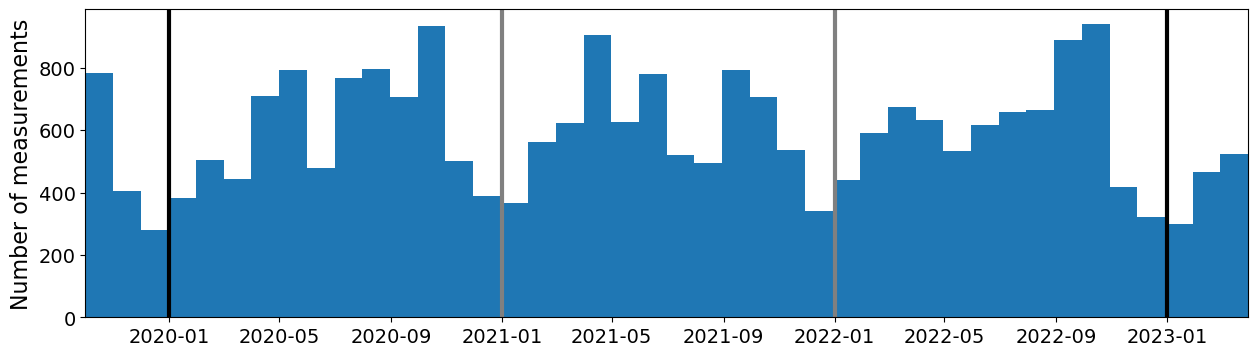

In [41]:
fig, ax = plt.subplots(figsize=(15, 4))
nbins=3*12+6
plt.hist(gosat_data.release_day,bins=nbins, range=(analysis_start_date,analysis_end_date))
plt.xlim(analysis_start_date,analysis_end_date)
plt.ylabel('Number of measurements',fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
#plt.xticks(coverage.columns,coverage.columns.strftime('%Y-%m'), rotation=45, ha='right',fontsize=12)
ax.axvline(dt.date(2020,1,1),color='black',linewidth=3)
ax.axvline(dt.date(2023,1,1),color='black',linewidth=3)
ax.axvline(dt.date(2022,1,1),color='grey',linewidth=3)
ax.axvline(dt.date(2021,1,1),color='grey',linewidth=3)
plt.savefig('figures_2/3years/gosat_measurements.pdf',dpi=500)



# Sanam Plot doctroal proposal

In [7]:
gosat_data

<xarray.Dataset> Size: 6GB
Dimensions:                                                (time: 80,
                                                            pointspec: 7276,
                                                            latitude: 22,
                                                            longitude: 36)
Coordinates:
  * time                                                   (time) datetime64[ns] 640B ...
  * pointspec                                              (pointspec) int64 58kB ...
  * latitude                                               (latitude) float32 88B ...
  * longitude                                              (longitude) float32 144B ...
    height                                                 float32 4B 30.0
Data variables: (12/22)
    spec001_mr                                             (time, pointspec, latitude, longitude) float32 2GB ...
    release_num                                            (pointspec) float64 58kB ...
    release_day                                            (pointspec) datetime64[ns] 58kB ...
    release_time                                           (pointspec) datetime64[ns] 58kB ...
    release_lat                                            (pointspec) float64 58kB ...
    release_lon                                            (pointspec) float64 58kB ...
    ...                                                     ...
    prior_val                                              (pointspec) float64 58kB ...
    posterior_val                                          (pointspec) float64 58kB ...
    ref_RemoteC_IS_val                                     (pointspec) float64 58kB ...
    prior_diff                                             (pointspec) float64 58kB ...
    posterior_diff                                         (pointspec) float64 58kB ...
    ref_RemoteC_IS_diff                                    (pointspec) float64 58kB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    ffadcb5 Fri Sep 19 15:51:15 2025 +0000
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-02-21 18:10 +0100  created by b383736 on l40...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          0
    sfc_only:               0
    linit_cond:             0

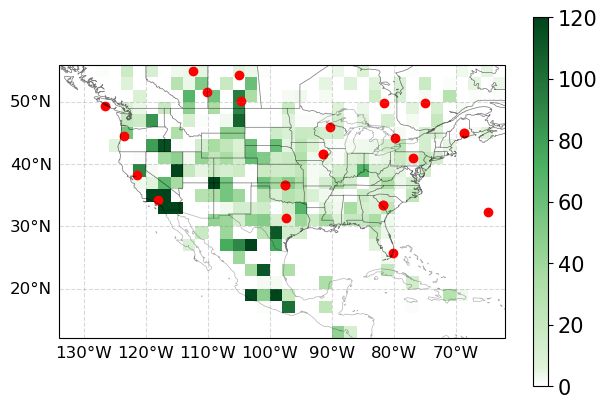

In [15]:
flexpart_region=[12,56,-134,-62]

from mpl_toolkits.axes_grid1 import make_axes_locatable

lat_centers = np.arange(flexpart_region[0] + 1, flexpart_region[1], 2)
lon_centers = np.arange(flexpart_region[2] + 1, flexpart_region[3], 2)

lat_idx = np.abs(gosat_data.release_lat.values[..., np.newaxis] - lat_centers).argmin(axis=-1)
lon_idx = np.abs(gosat_data.release_lon.values[..., np.newaxis] - lon_centers).argmin(axis=-1)
counts = np.zeros((len(lat_centers), len(lon_centers)), dtype=int)
for i, j in zip(lat_idx.ravel(), lon_idx.ravel()):
    counts[i, j] += 1


# Sum map counts along latitude/longitude
lon_counts = counts.sum(axis=0)
lat_counts = counts.sum(axis=1)


# ---------------------------------------------------------
# Figure layout
# ---------------------------------------------------------

fig = plt.figure(figsize=(9, 7))

# Map occupies bottom-right
ax_map = fig.add_axes([0.22, 0.15, 0.62, 0.62], projection=ccrs.PlateCarree())


# ---------------------------------------------------------
# Map
# ---------------------------------------------------------
cmap = LinearSegmentedColormap.from_list( 'white_green',[(0.00, 'white'), (0.05, plt.cm.Greens(0.15)), (0.30, plt.cm.Greens(0.35)), (0.60, plt.cm.Greens(0.60)), (1.00, plt.cm.Greens(1.00)) ])
# 0 -> white, 120 -> dark green
norm = Normalize(vmin=0, vmax=120)
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)
mesh = ax_map.pcolormesh(lon_grid, lat_grid, counts, cmap=cmap, norm=norm, shading='auto')
cbar = plt.colorbar(mesh, ax=ax_map, location='right', shrink=0.85, aspect=25, pad=0.05)
cbar.ax.tick_params(labelsize=15)
ax_map.coastlines(linewidth=0.5, alpha=0.3)
ax_map.add_feature( cfeature.STATES, edgecolor='black', linewidth=0.5, alpha=0.3)
gl = ax_map.gridlines( draw_labels=True, color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax_map.set_xlim(-134, -62)
ax_map.set_ylim(12, 56)
ax_map.tick_params(axis='both', labelsize=16)
fig.canvas.draw()

'''
ax_map.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax_map.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax_map.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
'''

map_pos = ax_map.get_position()

x0 = map_pos.x0
y0 = map_pos.y0
width = map_pos.width
height = map_pos.height


files=[f for f in np.unique(insitu_data.file.values)]

for f in files:
    temp=insitu_data.where(insitu_data.file==f,drop=True)
    ax_map.scatter(temp.release_lon[0], temp.release_lat[0], marker='o', color='red')

ax_map.set_aspect(380*(134-62)/(620*(56-12)))
plt.savefig(f'{savefig}/gosat_meas_distribution_insitu_distribution_2021.png',bbox_inches='tight')#,transparent=True)

plt.show()
